Scaling 
-reducing the interval
-for numerical column
two ways:
--works for col
    -standardization
     uses in machine learning
     mean=0, sd=1
    -normalization
     uses in deeplearning
     ranges between 0-1
--works for row
    -normalize
     convert rows into unit vector. magnitute=1

In [163]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler,MinMaxScaler

standardization

In [164]:
df=sns.load_dataset('tips')
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [165]:
df.shape

(244, 7)

In [166]:
df['size'].unique()

array([2, 3, 4, 1, 6, 5])

In [167]:
max(df['total_bill']),min(df['total_bill'])

(50.81, 3.07)

In [168]:
total_bill=list(df['total_bill'])

In [169]:
mean=np.mean(total_bill)
sd=np.std(total_bill)

In [170]:
mean,sd

(np.float64(19.78594262295082), np.float64(8.884150577771132))

In [171]:
normalized_data=[]
for i in total_bill:
    z=(i-mean)/sd
    normalized_data.append(z)

In [172]:
normalized_data

[np.float64(-0.3147113050904943),
 np.float64(-1.0632353132988692),
 np.float64(0.13777989987156145),
 np.float64(0.43831510316725475),
 np.float64(0.540744704290506),
 np.float64(0.6195367051545455),
 np.float64(-1.2399545152367863),
 np.float64(0.7985071071171495),
 np.float64(-0.5342033074974614),
 np.float64(-0.5634689078183903),
 np.float64(-1.0711145133852733),
 np.float64(1.7417599174609364),
 np.float64(-0.49143050702841123),
 np.float64(-0.15262490331304146),
 np.float64(-0.557840907756673),
 np.float64(0.2019391005751361),
 np.float64(-1.0643609133112126),
 np.float64(-0.3935033059545337),
 np.float64(-0.31696250511518104),
 np.float64(0.09725829942719795),
 np.float64(-0.2100305039425557),
 np.float64(0.05673669898283484),
 np.float64(-0.45203450659639155),
 np.float64(2.2100095225958003),
 np.float64(0.003833498402694168),
 np.float64(-0.2224121040783337),
 np.float64(-0.7221785095588127),
 np.float64(-0.7987193103981653),
 np.float64(0.21544630072325727),
 np.float64(-0.01

In [173]:
max(normalized_data),min(normalized_data)

(np.float64(3.492067936654957), np.float64(-1.8815465222725365))

In [174]:
np.mean(normalized_data),np.std(normalized_data)

(np.float64(-7.871663248366888e-17), np.float64(1.0))

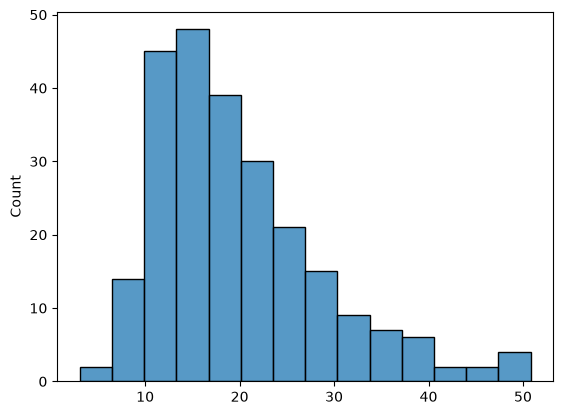

<Axes: ylabel='Count'>

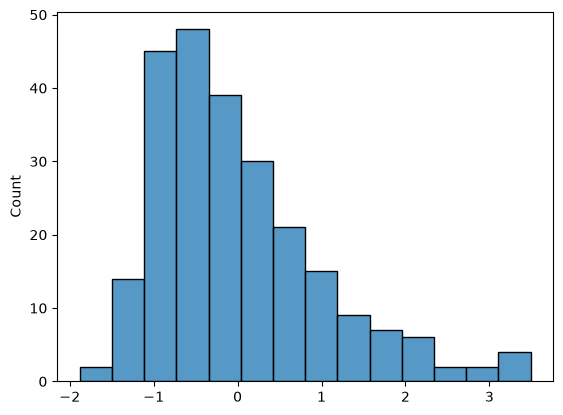

In [175]:
sns.histplot(total_bill)
plt.show()
sns.histplot(normalized_data)


above was using a formula now we will use method called standardscaler

In [176]:
scaler=StandardScaler()
scaler

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [177]:
scaler.fit(df[['total_bill', 'tip']])
scaler

StandardScaler()

In [178]:
data=scaler.transform(df[['total_bill','tip']])
data

array([[-3.14711305e-01, -1.43994695e+00],
       [-1.06323531e+00, -9.69205340e-01],
       [ 1.37779900e-01,  3.63355539e-01],
       [ 4.38315103e-01,  2.25754144e-01],
       [ 5.40744704e-01,  4.43019505e-01],
       [ 6.19536705e-01,  1.23965916e+00],
       [-1.23995452e+00, -7.22971264e-01],
       [ 7.98507107e-01,  8.81527488e-02],
       [-5.34203307e-01, -7.51939979e-01],
       [-5.63468908e-01,  1.67816714e-01],
       [-1.07111451e+00, -9.32994446e-01],
       [ 1.74175992e+00,  1.44968234e+00],
       [-4.91430507e-01, -1.03438495e+00],
       [-1.52624903e-01,  1.24660453e-03],
       [-5.57840908e-01,  1.57309619e-02],
       [ 2.01939101e-01,  6.67527044e-01],
       [-1.06436091e+00, -9.61963161e-01],
       [-3.93503306e-01,  5.15441291e-01],
       [-3.16962505e-01,  3.63355539e-01],
       [ 9.72582994e-02,  2.54722859e-01],
       [-2.10030504e-01,  7.83401903e-01],
       [ 5.67366990e-02, -1.79807863e-01],
       [-4.52034507e-01, -5.56401155e-01],
       [ 2.

In [179]:
data=scaler.fit_transform(df[["total_bill",'tip']])
df_scaled=pd.DataFrame(data, columns=['total_bill_standard','tip_standard'])
df_scaled.head()

,total_bill_standard,tip_standard
0,-0.314711,-1.439947
1,-1.063235,-0.969205
2,0.137780,0.363356
3,0.438315,0.225754
4,0.540745,0.443020


In [180]:
max(df_scaled['total_bill_standard']),min(df_scaled['total_bill_standard'])

(3.492067936654957, -1.8815465222725365)

In [181]:
np.mean(df_scaled['total_bill_standard']),np.std(df_scaled['total_bill_standard'])

(np.float64(-7.871663248366888e-17), np.float64(1.0))

normalization

In [182]:
df=sns.load_dataset('taxis')
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [183]:
min_max=MinMaxScaler()
min_max

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False


In [184]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


In [185]:
max(df['distance']),min(df['distance']),max(df['fare']),min(df['fare']),max(df['tip']),min(df['tip']),max(df['total']),min(df['total'])

(36.7, 0.0, 150.0, 1.0, 33.2, 0.0, 174.82, 1.3)

In [186]:
min_max.fit(df[['distance','fare','tip','total']])
min_max

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](4,)","[ 36.7 ,150. , 33.2 ,174.82]"
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](4,)","[0. ,1. ,0. ,1.3]"
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](4,)","[ 36.7 ,149. , 33.2 ,173.52]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['distance','fare','tip','total']"
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](4,)","[ 0. ,-0.01, 0. ,-0.01]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,6433


In [187]:
min_max.transform(df[['distance','fare','tip','total']])

array([[0.04359673, 0.04026846, 0.06475904, 0.06713923],
       [0.02152589, 0.02684564, 0.        , 0.0461042 ],
       [0.0373297 , 0.04362416, 0.07108434, 0.07411249],
       ...,
       [0.11280654, 0.10067114, 0.        , 0.09220839],
       [0.03051771, 0.03355705, 0.        , 0.03169663],
       [0.10490463, 0.09395973, 0.10120482, 0.10869064]], shape=(6433, 4))

In [191]:
df2=pd.DataFrame(min_max.fit_transform(df[['distance','fare','tip','total']]),columns=['distance','fare','tip','total'])
df2.head()

,distance,fare,tip,total
0,0.043597,0.040268,0.064759,0.067139
1,0.021526,0.026846,0.000000,0.046104
2,0.037330,0.043624,0.071084,0.074112
3,0.209809,0.174497,0.185241,0.205452
4,0.058856,0.053691,0.033133,0.069733


In [192]:
min(df2['total']),max(df2['total'])

(0.0, 1.0)